# 02 — Heart-rate estimation from wrist PPG

**Goal:** Estimate heart rate from the PPG signal, compare it with the ECG-derived reference, and understand where a simple method fails.

We'll try two straightforward approaches:
- **Raw PPG:** pick the strongest frequency in the pulse range using a periodogram.
- **Filtered PPG:** first apply a Butterworth bandpass filter, then pick the strongest frequency using Welch's spectrum.

No model training is required. **The reference heart rate is only used to evaluate predictions — never to estimate them.**

## 1. Load the subjects

Use the same subject IDs and dataset folder as in notebook 01. You can select **one or two subjects**; the code handles both. The times below are seconds from each participant's own recording start, so the same time does **not** guarantee the same activity for different subjects.

*Security: load pickle files only from the trusted dataset download; Python pickle can execute code during loading.*

In [1]:
import pickle
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal

SUBJECTS = ["S1", "S4"]
SUBJECTS = ["S1"]
DATA_FOLDER = Path("../Data/PPG_FieldStudy")

timeline = {"NO:_ACTIVITY1":	0,
 "BASELINE":	90,
 "NO_ACTIVITY2":	791,
 "STAIRS":	837,
 "NO_ACTIVITY3":	1125,
 "SOCCER":	1210,
 "NO_ACTIVITY4":	1556,
 "CYCLING":	1918,
 "NO_ACTIVITY5":	2331,
 "DRIVING":	2935,
 "NO_ACTIVITY6":	3825,
 "LUNCH":	4595,
 "WALKING":	6951,
 "NO_ACTIVITY7":	7706,
 "WORKING":	7791,
 "NO_ACTIVITY8":	8981,
 "CLEAN_BASELINE":	9077,
 "NO_ACTIVITY9":	9198}


GRAPH_START = timeline["DRIVING"] + 285
# GRAPH_START = timeline["CYCLING"] + 200
GRAPH_DURATION = 90


PPG_HZ = 64
ACC_HZ = 32
WINDOW = 8         # 8-second windows
STEP = 2           # Move forward 2 seconds each time
MIN_HZ = 0.65      # 39 BPM
MAX_HZ = 3.5       # 210 BPM

In [2]:
recordings = {}

for subject in SUBJECTS:
    file = DATA_FOLDER / subject / f"{subject}.pkl"
    with open(file, "rb") as f:
        data = pickle.load(f, encoding="latin1")

    recordings[subject] = {
        "ppg": np.asarray(data["signal"]["wrist"]["BVP"]).flatten(),
        "reference_hr": np.asarray(data["label"]).flatten(),
        "acc": np.asarray(data["signal"]["wrist"]["ACC"])
    }

    print(f"{subject}: {len(recordings[subject]['ppg']):,} PPG samples, "
          f"{len(recordings[subject]['reference_hr']):,} reference labels")

S1: 589,568 PPG samples, 4,603 reference labels


## 2. Build a simple heart-rate estimator

Heartbeats produce repeated fluctuations in PPG. We find a strong frequency between **0.65 and 3.5 Hz**, then multiply it by 60 to convert it to beats per minute.

The 8-second windows match the supplied reference labels: label 0 covers 0–8 seconds, label 1 covers 2–10 seconds, and so on. The `nfft=4096` setting makes the plotted peak smoother but **does not add information** to an 8-second recording.

**Important:** With a single 8-second window, Welch's method has effectively one segment, so it provides no averaging advantage over a periodogram. This is just a modest baseline comparison, not a robust motion-correction algorithm.

In [3]:
def estimate_hr(ppg_window, method="periodogram"):
    if not np.isfinite(ppg_window).all():
        return np.nan

    if method == "welch":
        freq, power = signal.welch(ppg_window, fs=PPG_HZ,
                                   nperseg=len(ppg_window), nfft=4096)
    else:
        freq, power = signal.periodogram(ppg_window, fs=PPG_HZ, nfft=4096)

    pulse_range = (freq >= MIN_HZ) & (freq <= MAX_HZ)
    peak = freq[pulse_range][np.argmax(power[pulse_range])]
    return peak * 60

## 3. Filter PPG and estimate heart rate

A third-order Butterworth bandpass filter retains frequencies near plausible pulse rates. We apply it to the full PPG recording **before** taking windows so each 8-second window doesn't have artificial filtering edges.

For every window we compute two predictions. **Only after that** do we retrieve the matching reference label for comparison.

In [4]:
results = {}

# Butterworth bandpass filter (0.7–3.5 Hz)
sos = signal.butter(
    3,
    [0.7, 3.5],
    btype="bandpass",
    fs=PPG_HZ,
    output="sos"
)

for subject in SUBJECTS:
    ppg = recordings[subject]["ppg"]
    reference_hr = recordings[subject]["reference_hr"]

    last_index = min(
        len(reference_hr) - 1,
        (len(ppg) - WINDOW * PPG_HZ) // (STEP * PPG_HZ)
    )

    assert last_index >= 0, f"{subject}: recording is too short."
    assert np.isfinite(ppg).all(), f"{subject}: PPG contains missing/non-finite values."

    filtered_ppg = signal.sosfiltfilt(sos, ppg)
    recordings[subject]["filtered_ppg"] = filtered_ppg

    rows = []
    for i in range(last_index + 1):
        start = i * STEP * PPG_HZ
        end = start + WINDOW * PPG_HZ

        raw_bpm = estimate_hr(ppg[start:end], method="welch")
        filtered_bpm = estimate_hr(filtered_ppg[start:end], method="welch")

        rows.append({
            "Time (s)": i * STEP + WINDOW / 2,
            "Raw estimate (BPM)": raw_bpm,
            "Filtered estimate (BPM)": filtered_bpm,
            "Reference HR (BPM)": reference_hr[i]
        })

    results[subject] = pd.DataFrame(rows)
    print(f"{subject}: {len(results[subject])} complete windows analyzed")

display(results[SUBJECTS[0]].head())

S1: 4603 complete windows analyzed


,Time (s),Raw estimate (BPM),Filtered estimate (BPM),Reference HR (BPM)
0,4.0,44.0625,45.0000,49.611369
1,6.0,43.1250,46.8750,50.323992
2,8.0,53.4375,53.4375,52.708336
3,10.0,52.5000,52.5000,55.640794
4,12.0,53.4375,52.5000,57.658406


## 4. Visualize the raw and filtered PPG

Inspect the **first 8 seconds** of the selected segment. The filter reduces out-of-band variation; it doesn't guarantee that the remaining peaks are genuine heartbeats.

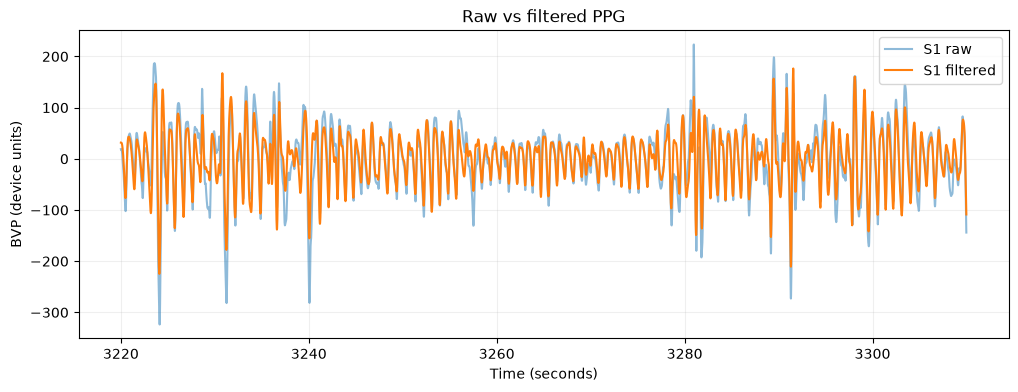

In [5]:
plt.figure(figsize=(12, 4))

for subject in SUBJECTS:
    ppg = recordings[subject]["ppg"]
    filtered_ppg = recordings[subject]["filtered_ppg"]

    start = int(GRAPH_START * PPG_HZ)
    end = int((GRAPH_START + GRAPH_DURATION) * PPG_HZ)

    assert end <= len(ppg), f"{subject}: graph segment exceeds recording."
    time = np.arange(start, end) / PPG_HZ

    plt.plot(time, ppg[start:end], alpha=0.5, label=f"{subject} raw")
    plt.plot(time, filtered_ppg[start:end], label=f"{subject} filtered")

plt.title("Raw vs filtered PPG")
plt.xlabel("Time (seconds)")
plt.ylabel("BVP (device units)")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

## 5. See how the frequency peak becomes a heart-rate estimate

The graph shows the spectral power at candidate pulse rates for the same 8-second window. The strongest peak within the chosen range is our estimate, **not proof of a true heartbeat**.

S1: estimated HR = 69.4 BPM


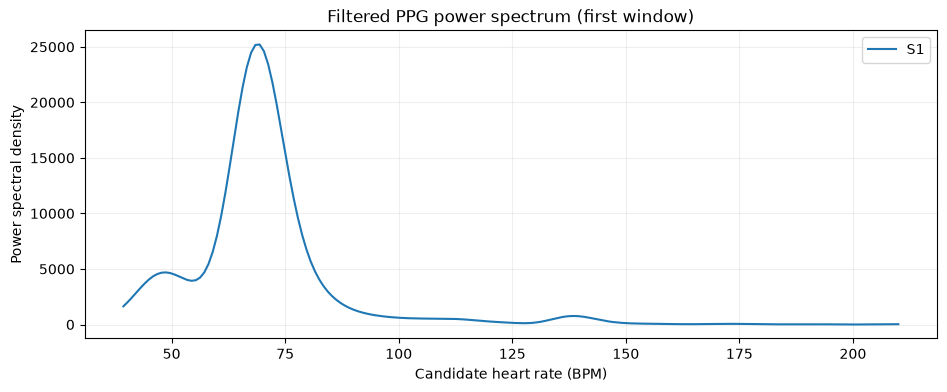

In [6]:
plt.figure(figsize=(11, 4))

for subject in SUBJECTS:
    ppg = recordings[subject]["filtered_ppg"]
    start = int(GRAPH_START * PPG_HZ)
    window = ppg[start:start + WINDOW * PPG_HZ]

    freq, power = signal.welch(window, fs=PPG_HZ,
                               nperseg=len(window), nfft=4096)
    pulse_range = (freq >= MIN_HZ) & (freq <= MAX_HZ)

    plt.plot(freq[pulse_range] * 60, power[pulse_range], label=subject)
    print(f"{subject}: estimated HR = {estimate_hr(window, method='welch'):.1f} BPM")

plt.title("Filtered PPG power spectrum (first window)")
plt.xlabel("Candidate heart rate (BPM)")
plt.ylabel("Power spectral density")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

## 6. Compare predictions with the reference

The ECG-derived reference is used **only here**, after both PPG estimates have been computed. Each plot compares a subject's estimates and reference over the selected interval.

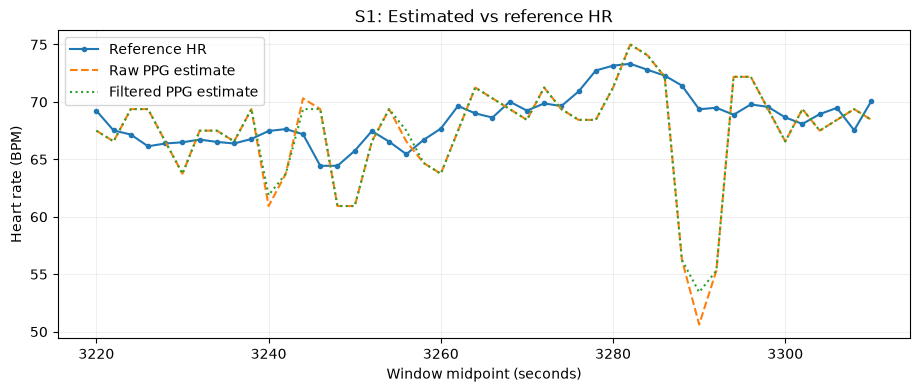

In [7]:
for subject in SUBJECTS:
    df = results[subject]

    # Filter only what is displayed, not the calculated results
    df = df[
        (df["Time (s)"] >= GRAPH_START) &
        (df["Time (s)"] <= GRAPH_START + GRAPH_DURATION)
    ]

    plt.figure(figsize=(11, 4))
    plt.plot(df["Time (s)"], df["Reference HR (BPM)"], label="Reference HR", marker=".")
    plt.plot(df["Time (s)"], df["Raw estimate (BPM)"], label="Raw PPG estimate", linestyle="--")
    plt.plot(df["Time (s)"], df["Filtered estimate (BPM)"], label="Filtered PPG estimate", linestyle=":")

    plt.title(f"{subject}: Estimated vs reference HR")
    plt.xlabel("Window midpoint (seconds)")
    plt.ylabel("Heart rate (BPM)")
    plt.legend()
    plt.grid(alpha=0.2)
    plt.show()

## 7. Measure estimation error

- **MAE (BPM):** average absolute difference between prediction and reference; lower is better.
- **Mean error (BPM):** average signed difference; positive values mean overestimation.

These metrics describe **only the chosen recording segment**, not performance on new participants. The overlapping windows aren't independent observations.

In [8]:
summary = []

for subject in SUBJECTS:
    df = results[subject]

    for method in ["Raw estimate (BPM)", "Filtered estimate (BPM)"]:
        error = df[method] - df["Reference HR (BPM)"]
        error = error.dropna()

        summary.append({
            "Subject": subject,
            "Method": method.replace(" estimate (BPM)", " PPG"),
            "Windows": len(error),
            "MAE (BPM)": error.abs().mean(),
            "Mean error (BPM)": error.mean()
        })

summary = pd.DataFrame(summary)
display(summary.round(2))

,Subject,Method,Windows,MAE (BPM),Mean error (BPM)
0,S1,Raw PPG,4603,12.00,-6.31
1,S1,Filtered PPG,4603,10.05,-2.77


## 8. Takeaways (fill in after running on the real data)

Write your own observations from the graphs and metrics:

- **Selected segment / activity:** …
- **Was the PPG waveform clean or distorted?** …
- **Did filtering improve MAE for S1 and/or S2?** …
- **Where were the largest errors?** …
- **What didn't work?** …
- **Limitations:** movement can create false peaks; the largest spectral peak may be a harmonic rather than the pulse; short windows limit frequency resolution; only a small number of participants and windows were evaluated; one 8-second Welch segment does not offer spectral averaging.

**Next:** More detailed evaluation, potentially comparing subjects during the *same activity* rather than using identical timestamps.

# Another Approach

### Extract features from the time series
Instead of giving the model 512 raw PPG measurements per window, we'll calculate useful features describing each window.

The spectral peak is included, so the model can learn when that baseline estimate is trustworthy. Accelerometer features provide information about movement that the spectral estimator currently ignores.

In [9]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

feature_rows = []

for subject in SUBJECTS:
    ppg = recordings[subject]["ppg"]
    filtered = recordings[subject]["filtered_ppg"]
    acc = recordings[subject]["acc"]
    reference_hr = recordings[subject]["reference_hr"]

    n_windows = min(
        len(reference_hr),
        (len(ppg) - WINDOW * PPG_HZ) // (STEP * PPG_HZ) + 1,
        (len(acc) - WINDOW * ACC_HZ) // (STEP * ACC_HZ) + 1
    )

    for i in range(n_windows):
        ppg_start = i * STEP * PPG_HZ
        acc_start = i * STEP * ACC_HZ

        raw = ppg[ppg_start:ppg_start + WINDOW * PPG_HZ]
        x = filtered[ppg_start:ppg_start + WINDOW * PPG_HZ]
        a = acc[acc_start:acc_start + WINDOW * ACC_HZ]

        # Frequency features
        freq, power = signal.welch(
            x, fs=PPG_HZ, nperseg=len(x), nfft=4096
        )

        pulse_range = (freq >= MIN_HZ) & (freq <= MAX_HZ)
        f = freq[pulse_range]
        p = power[pulse_range]
        p_norm = p / (p.sum() + 1e-12)

        # Movement features
        movement = np.linalg.norm(a, axis=1)

        feature_rows.append({
            "Subject": subject,
            "Time (s)": i * STEP + WINDOW / 2,
            "Reference HR (BPM)": reference_hr[i],

            "Spectral BPM": f[np.argmax(p)] * 60,
            "Spectral peak fraction": p_norm.max(),
            "Spectral entropy": -(p_norm * np.log(p_norm + 1e-12)).sum(),
            "Low-band fraction": p_norm[f < 1.3].sum(),
            "High-band fraction": p_norm[f >= 2.2].sum(),

            "Filtered PPG std": np.std(x),
            "Raw PPG std": np.std(raw),

            "ACC magnitude std": np.std(movement),
            "ACC change": np.mean(np.abs(np.diff(movement))),
            "ACC X std": np.std(a[:, 0]),
            "ACC Y std": np.std(a[:, 1]),
            "ACC Z std": np.std(a[:, 2])
        })

features = pd.DataFrame(feature_rows).dropna().reset_index(drop=True)

display(features.head())
print("Total windows:", len(features))

,Subject,Time (s),Reference HR (BPM),Spectral BPM,Spectral peak fraction,Spectral entropy,Low-band fraction,High-band fraction,Filtered PPG std,Raw PPG std,ACC magnitude std,ACC change,ACC X std,ACC Y std,ACC Z std
0,S1,4.0,49.611369,45.0000,0.030782,4.448252,0.537652,0.057232,44.881519,61.065445,0.071625,0.024884,0.120019,0.143626,0.236838
1,S1,6.0,50.323992,46.8750,0.024294,4.578775,0.583435,0.064407,48.574633,64.306610,0.073404,0.029136,0.124944,0.141129,0.227485
2,S1,8.0,52.708336,53.4375,0.048604,3.969279,0.812202,0.037275,53.829948,68.936994,0.069871,0.035023,0.097398,0.132428,0.105208
3,S1,10.0,55.640794,52.5000,0.056316,3.999650,0.816239,0.031511,49.035845,59.688771,0.071553,0.029045,0.255328,0.276344,0.101971
4,S1,12.0,57.658406,52.5000,0.054151,4.057292,0.770767,0.043118,56.715631,67.241022,0.126706,0.048286,0.293226,0.339184,0.237332


Total windows: 4603


### Chronological train/validation/test split
Now we split each participant's recording in chronological order.
Each participant's recording
Train 60% - Val 20% - Test 20%


Small gaps at the split boundaries exclude overlapping windows.
Because the windows are 8 seconds long but begin every 2 seconds, neighboring samples share most of their measurements. We therefore skip several windows between sets.

In [10]:
feature_cols = [
    "Spectral BPM",
    "Spectral peak fraction",
    "Spectral entropy",
    "Low-band fraction",
    "High-band fraction",
    "Filtered PPG std",
    "Raw PPG std",
    "ACC magnitude std",
    "ACC change",
    "ACC X std",
    "ACC Y std",
    "ACC Z std"
]

target = "Reference HR (BPM)"

GAP = int(np.ceil(WINDOW / STEP))

train_parts = []
val_parts = []
test_parts = []

for subject in SUBJECTS:
    df = features[features["Subject"] == subject]
    df = df.sort_values("Time (s)")

    n = len(df)
    train_end = int(n * 0.6)
    val_end = int(n * 0.8)

    train_parts.append(df.iloc[:train_end])
    val_parts.append(df.iloc[train_end + GAP:val_end])
    test_parts.append(df.iloc[val_end + GAP:])

train = pd.concat(train_parts, ignore_index=True)
val = pd.concat(val_parts, ignore_index=True)
test = pd.concat(test_parts, ignore_index=True)

print("Train:", len(train))
print("Validation:", len(val))
print("Test:", len(test))

Train: 2761
Validation: 917
Test: 917


,Correlation
ACC change,0.776
ACC magnitude std,0.752
ACC Y std,0.724
Low-band fraction,-0.653
Spectral BPM,0.593
Filtered PPG std,0.528
ACC X std,0.507
ACC Z std,0.495
Raw PPG std,0.476
High-band fraction,0.359


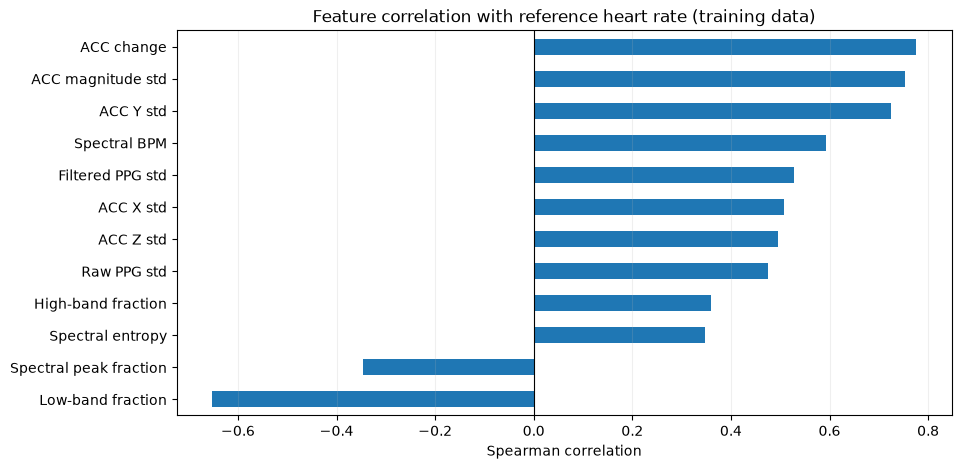

In [11]:
# Correlation between features and reference heart rate
correlations = train[feature_cols + [target]].corr(
    method="spearman"
)[target].drop(target)

correlations = correlations.reindex(
    correlations.abs().sort_values(ascending=False).index
)

display(correlations.to_frame("Correlation").round(3))

plt.figure(figsize=(10, 5))
correlations.sort_values().plot(kind="barh")

plt.title("Feature correlation with reference heart rate (training data)")
plt.xlabel("Spearman correlation")
plt.axvline(0, color="black", linewidth=0.8)
plt.grid(axis="x", alpha=0.2)
plt.show()

### Train and select a model
We'll compare two modest gradient-boosting configurations using the validation set, then select the one with lower validation MAE.

No random split, no deep learning, and no GPU.

In [12]:
configs = [
    {"max_iter": 150, "max_leaf_nodes": 15},
    {"max_iter": 250, "max_leaf_nodes": 31}
]

validation_scores = []

for config in configs:
    model = HistGradientBoostingRegressor(
        learning_rate=0.05,
        l2_regularization=1.0,
        early_stopping=False,
        random_state=42,
        **config
    )

    model.fit(train[feature_cols], train[target])

    predictions = model.predict(val[feature_cols])
    mae = mean_absolute_error(val[target], predictions)

    validation_scores.append(mae)

    print(f"{config}: Validation MAE = {mae:.2f} BPM")

{'max_iter': 150, 'max_leaf_nodes': 15}: Validation MAE = 4.90 BPM
{'max_iter': 250, 'max_leaf_nodes': 31}: Validation MAE = 4.90 BPM


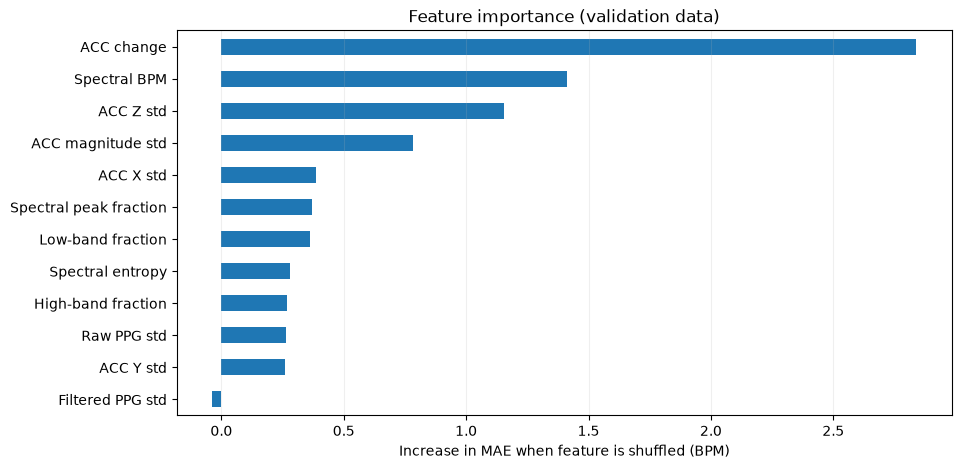

In [13]:
from sklearn.inspection import permutation_importance

best_config = configs[np.argmin(validation_scores)]
# Train on training data only
importance_model = HistGradientBoostingRegressor(
    learning_rate=0.05,
    l2_regularization=1.0,
    early_stopping=False,
    random_state=42,
    **best_config
)

importance_model.fit(train[feature_cols], train[target])

# Measure feature importance using validation data
importance = permutation_importance(
    importance_model,
    val[feature_cols],
    val[target],
    scoring="neg_mean_absolute_error",
    n_repeats=5,
    random_state=42
)

importance_scores = pd.Series(
    importance.importances_mean,
    index=feature_cols
).sort_values()

plt.figure(figsize=(10, 5))
importance_scores.plot(kind="barh")

plt.title("Feature importance (validation data)")
plt.xlabel("Increase in MAE when feature is shuffled (BPM)")
plt.grid(axis="x", alpha=0.2)
plt.show()

In [18]:
acc_features = [col for col in feature_cols if col.startswith("ACC")]
ppg_features = [col for col in feature_cols if col not in acc_features]

experiments = {
    "PPG only": ppg_features,
    "ACC only": acc_features,
    "PPG + ACC": feature_cols
}

scores = []

# Original spectral baseline
baseline_mae = mean_absolute_error(val[target], val["Spectral BPM"])

scores.append({
    "Model": "Spectral baseline",
    "Validation MAE": baseline_mae
})

# Train models with different feature groups
for name, cols in experiments.items():
    candidate = HistGradientBoostingRegressor(
        learning_rate=0.05,
        l2_regularization=1.0,
        early_stopping=False,
        random_state=42,
        **best_config
    )

    candidate.fit(train[cols], train[target])
    predictions = candidate.predict(val[cols])

    scores.append({
        "Model": name,
        "Validation MAE": mean_absolute_error(val[target], predictions)
    })

ablation_results = pd.DataFrame(scores)
display(ablation_results.sort_values("Validation MAE").round(2))

,Model,Validation MAE
3,PPG + ACC,4.90
2,ACC only,5.28
1,PPG only,7.62
0,Spectral baseline,9.59


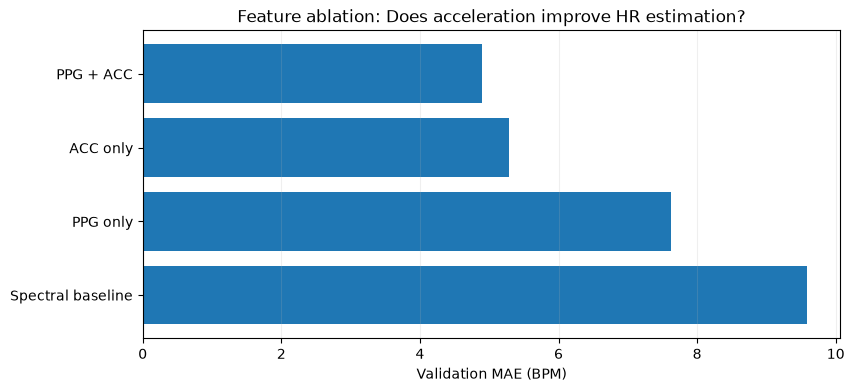

In [19]:
ablation_results = ablation_results.sort_values("Validation MAE")

plt.figure(figsize=(9, 4))
plt.barh(ablation_results["Model"], ablation_results["Validation MAE"])

plt.xlabel("Validation MAE (BPM)")
plt.title("Feature ablation: Does acceleration improve HR estimation?")
plt.grid(axis="x", alpha=0.2)
plt.gca().invert_yaxis()
plt.show()

,Removed feature,Validation MAE,MAE increase
0,Spectral BPM,5.381,0.485
5,Filtered PPG std,4.982,0.087
11,ACC Z std,4.973,0.078
7,ACC magnitude std,4.939,0.043
10,ACC Y std,4.929,0.033
3,Low-band fraction,4.924,0.029
6,Raw PPG std,4.914,0.019
1,Spectral peak fraction,4.905,0.009
9,ACC X std,4.896,0.001
2,Spectral entropy,4.875,-0.021


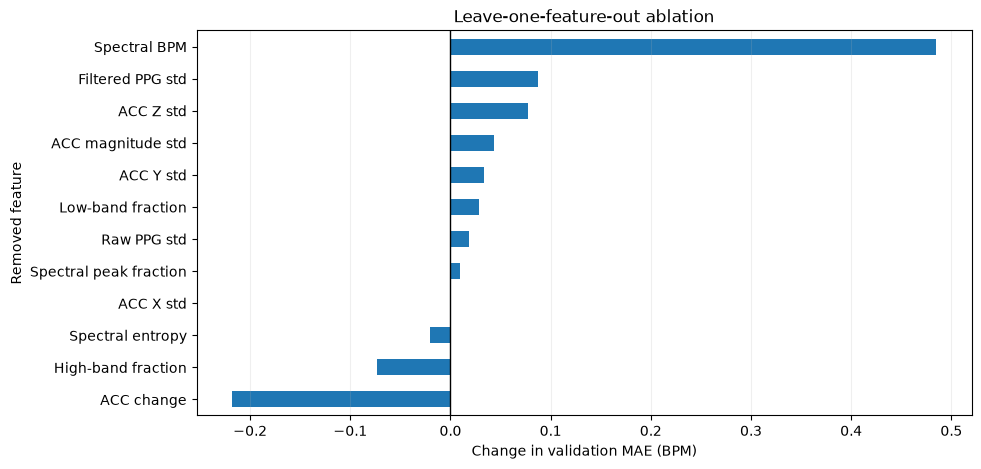

In [20]:
ablation_scores = []

for removed_feature in feature_cols:
    cols = [f for f in feature_cols if f != removed_feature]

    candidate = HistGradientBoostingRegressor(
        learning_rate=0.05,
        l2_regularization=1.0,
        early_stopping=False,
        random_state=42,
        **best_config
    )

    candidate.fit(train[cols], train[target])
    predictions = candidate.predict(val[cols])

    ablation_scores.append({
        "Removed feature": removed_feature,
        "Validation MAE": mean_absolute_error(val[target], predictions)
    })

ablation_scores = pd.DataFrame(ablation_scores)

# Compare against the model trained with all features
full_mae = ablation_results.loc[
    ablation_results["Model"] == "PPG + ACC",
    "Validation MAE"
].iloc[0]

ablation_scores["MAE increase"] = (
    ablation_scores["Validation MAE"] - full_mae
)

display(ablation_scores.sort_values("MAE increase", ascending=False).round(3))

plt.figure(figsize=(10, 5))
ablation_scores.set_index("Removed feature")["MAE increase"].sort_values().plot(
    kind="barh"
)

plt.axvline(0, color="black", linewidth=1)
plt.xlabel("Change in validation MAE (BPM)")
plt.title("Leave-one-feature-out ablation")
plt.grid(axis="x", alpha=0.2)
plt.show()

In [21]:
# Feature configurations
feature_sets = {
    "All features": feature_cols,
    "Without ACC change": [
        f for f in feature_cols if f != "ACC change"
    ],
    "Reduced features": [
        f for f in feature_cols
        if f not in ["ACC change", "High-band fraction", "Spectral entropy"]
    ]
}

validation_results = []

# Compare configurations on validation data
for name, cols in feature_sets.items():
    candidate = HistGradientBoostingRegressor(
        learning_rate=0.05,
        l2_regularization=1.0,
        early_stopping=False,
        random_state=42,
        **best_config
    )

    candidate.fit(train[cols], train[target])
    predictions = candidate.predict(val[cols])

    mae = mean_absolute_error(val[target], predictions)

    validation_results.append({
        "Model": name,
        "Features": len(cols),
        "Validation MAE": mae
    })

# Show comparison
comparison = pd.DataFrame(validation_results).sort_values("Validation MAE")
display(comparison.round(3))

# Select best configuration
best_name = comparison.iloc[0]["Model"]
selected_features = feature_sets[best_name]

print(f"\nBest configuration: {best_name}")
print(f"Validation MAE: {comparison.iloc[0]['Validation MAE']:.3f} BPM")
print(f"\nSelected features ({len(selected_features)}):")

for feature in selected_features:
    print(f"  - {feature}")

print("\nRemoved features:", set(feature_cols) - set(selected_features))

# Retrain the final model on train + validation data
final_train = pd.concat([train, val], ignore_index=True)

model = HistGradientBoostingRegressor(
    learning_rate=0.05,
    l2_regularization=1.0,
    early_stopping=False,
    random_state=42,
    **best_config
)

model.fit(final_train[selected_features], final_train[target])

# Predict on the untouched test set
test = test.copy()
test["ML estimate (BPM)"] = model.predict(test[selected_features])

,Model,Features,Validation MAE
1,Without ACC change,11,4.677
2,Reduced features,9,4.703
0,All features,12,4.896



Best configuration: Without ACC change
Validation MAE: 4.677 BPM

Selected features (11):
  - Spectral BPM
  - Spectral peak fraction
  - Spectral entropy
  - Low-band fraction
  - High-band fraction
  - Filtered PPG std
  - Raw PPG std
  - ACC magnitude std
  - ACC X std
  - ACC Y std
  - ACC Z std

Removed features: {'ACC change'}


### Train the final model
Once we've selected the configuration, we'll train on the combined training and validation sets, then predict the final test set.

In [ ]:
model = HistGradientBoostingRegressor(
    learning_rate=0.05,
    l2_regularization=0.7,
    early_stopping=True,
    random_state=42,
    **best_config
)

final_train = pd.concat([train, val], ignore_index=True)

model.fit(final_train[feature_cols], final_train[target])

test = test.copy()
test["ML estimate (BPM)"] = model.predict(test[feature_cols])

print("Selected configuration:", best_config)

Selected configuration: {'max_iter': 250, 'max_leaf_nodes': 31}


### Compare against the baseline
This is where we find out whether training a model actually improved anything.

We'll compare the trained regressor with your existing filtered PPG spectral estimator, using only the held-out test windows.

In [15]:
scores = []

for subject in SUBJECTS:
    df = test[test["Subject"] == subject]

    for name, column in [
        ("Spectral baseline", "Spectral BPM"),
        ("Gradient boosting", "ML estimate (BPM)")
    ]:
        mae = mean_absolute_error(df[target], df[column])
        rmse = np.sqrt(mean_squared_error(df[target], df[column]))

        scores.append({
            "Subject": subject,
            "Method": name,
            "MAE (BPM)": mae,
            "RMSE (BPM)": rmse
        })

scores = pd.DataFrame(scores)
display(scores.round(2))

,Subject,Method,MAE (BPM),RMSE (BPM)
0,S1,Spectral baseline,6.83,13.26
1,S1,Gradient boosting,5.57,8.17


### Visualize the model's predictions
Let's compare predictions and reference heart rate over a segment of each subject's test data.

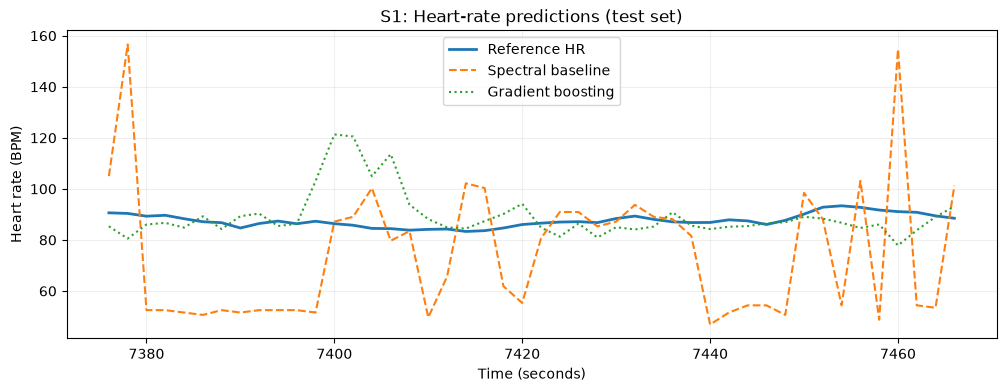

In [16]:
for subject in SUBJECTS:
    df = test[test["Subject"] == subject]

    # Start from the first test window
    start = df["Time (s)"].min()
    df = df[df["Time (s)"] <= start + GRAPH_DURATION]

    plt.figure(figsize=(12, 4))

    plt.plot(df["Time (s)"], df[target],
             label="Reference HR", linewidth=2)

    plt.plot(df["Time (s)"], df["Spectral BPM"],
             label="Spectral baseline", linestyle="--")

    plt.plot(df["Time (s)"], df["ML estimate (BPM)"],
             label="Gradient boosting", linestyle=":")

    plt.title(f"{subject}: Heart-rate predictions (test set)")
    plt.xlabel("Time (seconds)")
    plt.ylabel("Heart rate (BPM)")
    plt.legend()
    plt.grid(alpha=0.2)
    plt.show()

### Does movement affect the model's accuracy?
One extra experiment I'd include is checking whether errors increase as wrist movement becomes stronger.

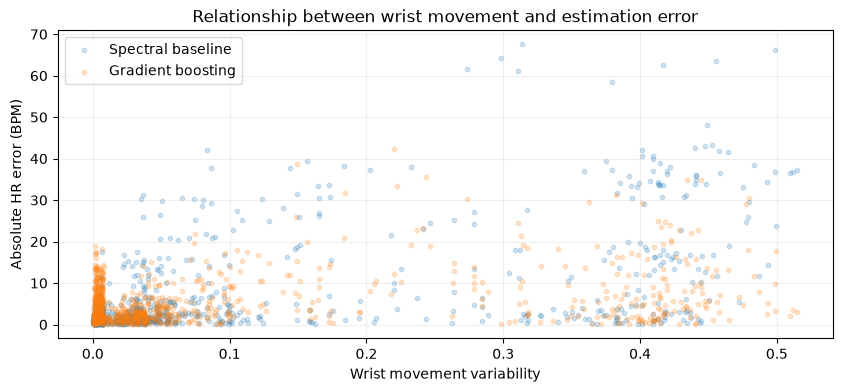

In [17]:
test["Baseline error"] = abs(test["Spectral BPM"] - test[target])
test["ML error"] = abs(test["ML estimate (BPM)"] - test[target])

plt.figure(figsize=(10, 4))

plt.scatter(
    test["ACC magnitude std"],
    test["Baseline error"],
    alpha=0.2, s=10,
    label="Spectral baseline"
)

plt.scatter(
    test["ACC magnitude std"],
    test["ML error"],
    alpha=0.2, s=10,
    label="Gradient boosting"
)

plt.xlabel("Wrist movement variability")
plt.ylabel("Absolute HR error (BPM)")
plt.title("Relationship between wrist movement and estimation error")
plt.legend()
plt.grid(alpha=0.2)
plt.show()